---
numbering: false
---

# 7.1: Least squares problems

So far, we've spent a lot of time trying to solve systems of the form

$$A\vec x=\vec b.$$

We've asked whether there is a solution and, if so, how many solutions there are. Now we want to answer a different question: **Suppose there isn't a solution. Among all vectors in the column space of $A$, which one is closest to $\vec b$?** In other words, how close can $A\vec x$ get to $\vec b$?

This question leads to **least squares**, an idea with applications throughout science, engineering, and machine learning. Let's start with a problem that makes the question concrete.

In [1]:
from least_squares_visuals import show_png


---

## A line that cannot pass through every point

Suppose we collect some measurements and want to describe their relationship using a line

$$y=mx+b.$$

The slope and intercept let us summarize a trend and predict new values. But measurements are often noisy, and a line is often only an approximation to the relationship. What should we do when no line passes through all the points exactly?

For a small example, consider these four points:

| Input | Measured output |
| --- | --- |
| $3$ | $5$ |
| $2$ | $2$ |
| $7$ | $7$ |
| $6$ | $8$ |

No single line passes through all four points. We still want a useful line, so we need to decide what it means for one line to fit these points **better** than another.


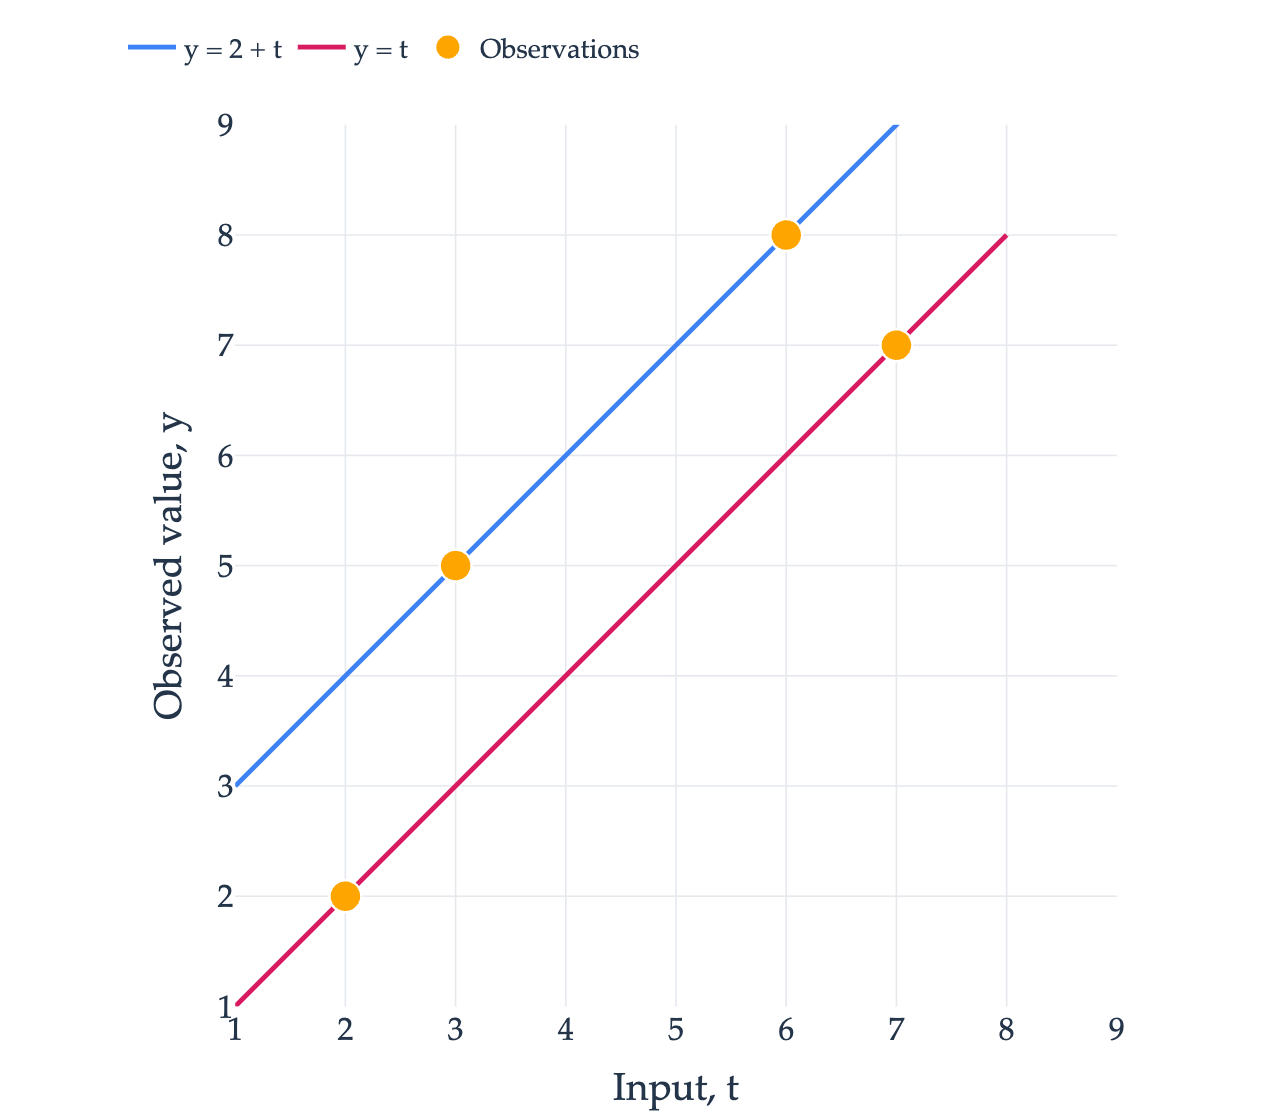

In [2]:
show_png("candidate-lines")

---

## Turning the data into equations

We'll write our model as

$$y=c+mt.$$

Here, $t$ is the input, $c$ is the intercept, and $m$ is the slope. We've changed the letters so that $\vec x$ can mean the vector of unknown coefficients and $\vec b$ can mean the vector of measured outputs.

Passing through all four points would require

$$\begin{aligned}
c+3m&=5,\\
c+2m&=2,\\
c+7m&=7,\\
c+6m&=8.
\end{aligned}$$

These equations have the form $A\vec x=\vec b$, where

$$\underbrace{\begin{bmatrix}1&3\\1&2\\1&7\\1&6\end{bmatrix}}_A
\underbrace{\begin{bmatrix}c\\m\end{bmatrix}}_{\vec x}
=\underbrace{\begin{bmatrix}5\\2\\7\\8\end{bmatrix}}_{\vec b}.$$

In statistics, $A$ is called the **design matrix**. Each **row** corresponds to one measurement. Each **column** corresponds to one coefficient: the first column records how the intercept contributes to each prediction, and the second records how the slope contributes. The inputs need not be sorted; each row of $A$ must stay matched to the corresponding entry of $\vec b$.

Even though there is no exact solution, the matrix makes predictions for any choice of coefficients:

$$A\vec x
=\begin{bmatrix}c+3m\\c+2m\\c+7m\\c+6m\end{bmatrix}.$$

Our goal is to make this vector of **predicted outputs** as close as possible to the vector of **measured outputs**, $\vec b$.


---

## Measuring the error

For any proposed coefficients $\vec x$, define the **error vector** to be

$$\vec r=\vec b-A\vec x.$$

Each entry is a measured output minus its predicted output. A positive error means the model predicts too low; a negative error means it predicts too high.

For example, the line $y=t$ has coefficient vector

$$\vec x=\begin{bmatrix}0\\1\end{bmatrix}.$$

Its predictions and error vector are

$$A\vec x=\begin{bmatrix}3\\2\\7\\6\end{bmatrix},
\qquad
\vec r=\begin{bmatrix}5\\2\\7\\8\end{bmatrix}-\begin{bmatrix}3\\2\\7\\6\end{bmatrix}
=\begin{bmatrix}2\\0\\0\\2\end{bmatrix}.$$

The second and third points lie on the line. The line predicts $2$ too low at the first and fourth points.

The length $\|\vec r\|$ measures the distance between the predicted-output vector and the measured-output vector. It is usually easier to work with its square:

$$\|\vec r\|^2=2^2+0^2+0^2+2^2=8.$$

Minimizing the length and minimizing its square give the same answer, since lengths are nonnegative. Squaring also makes the contributions from positive and negative errors count toward the error instead of canceling each other.


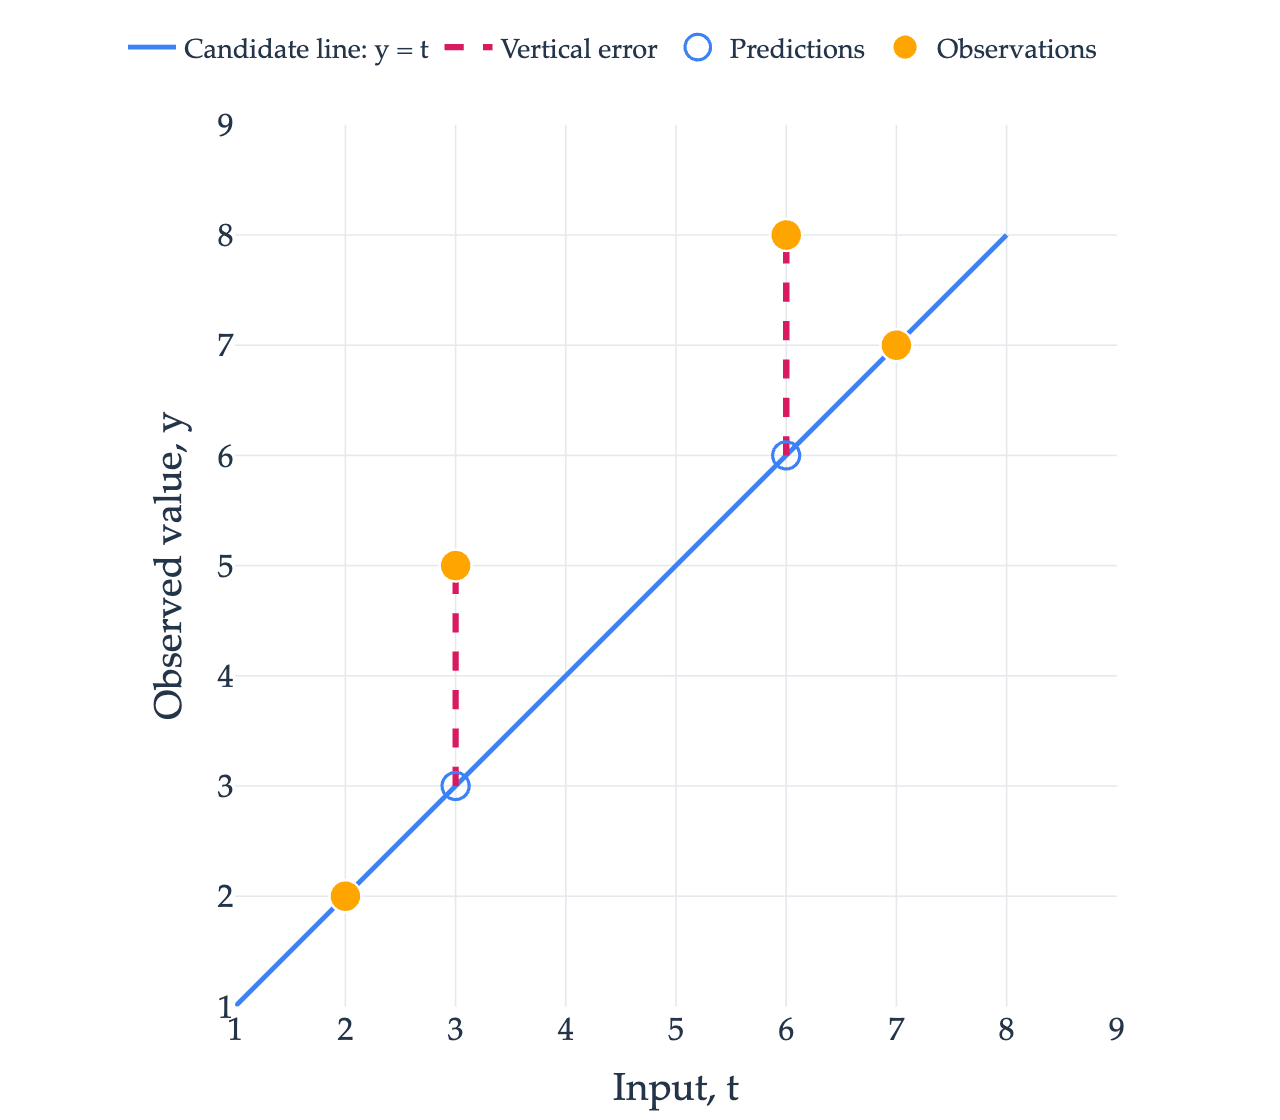

In [3]:
show_png("candidate-errors")


::::{tip} Activity 1: Comparing two lines
Keep the same four data points, and consider the line $y=2+t$.

**a)** Write its coefficient vector $\vec x$. Find the predicted-output vector $A\vec x$ and the error vector $\vec r=\vec b-A\vec x$.

**b)** Calculate $\|\vec r\|^2$. Compare the fits of $y=2+t$ and $y=t$.

**c)** Does comparing these two lines establish which line is best among **all** lines?

:::{tip} Solution
:class: dropdown

**a)** The coefficient vector, predictions, and error vector are

$$\vec x=\begin{bmatrix}2\\1\end{bmatrix},\qquad
A\vec x=\begin{bmatrix}5\\4\\9\\8\end{bmatrix},\qquad
\vec r=\begin{bmatrix}0\\-2\\-2\\0\end{bmatrix}.$$

**b)** The squared error length is

$$\|\vec r\|^2=0^2+(-2)^2+(-2)^2+0^2=8.$$

The line $y=t$ also has squared error length $8$. The two lines fit equally well by this measure.

**c)** No. We have compared only two possibilities. In fact, neither line is the best possible fit; we'll find a better one in [Chapter 7.2](07-02.ipynb).
:::
::::


The errors in the data plot are **vertical differences**, measured at the given input values. We are not measuring the shortest perpendicular distances from the plotted points to the fitted line.

Later, we will use a perpendicular projection to find the best fit. That projection takes place in a different space: the space of output vectors. Keeping these two pictures separate will help us interpret the geometry.

---

## The column space picture

Recall from [Chapter 5.1](../ch05/05-01.ipynb) that $\operatorname{colsp}(A)$ is the set of all possible outputs of $A$. In our example,

$$A\vec x
=c\begin{bmatrix}1\\1\\1\\1\end{bmatrix}
+m\begin{bmatrix}3\\2\\7\\6\end{bmatrix}.$$

The two columns are independent, so their span is a **two-dimensional plane through the origin in $\mathbb R^4$**. Every vector in this plane is a vector of predictions produced by some line $y=c+mt$.

Our measured-output vector is

$$\vec b=\begin{bmatrix}5\\2\\7\\8\end{bmatrix}.$$

It lies outside that plane, because the original system has no solution. Changing $c$ and $m$ moves $A\vec x$ within the plane, but can never make $A\vec x$ equal to $\vec b$.

We can now restate the fitting problem geometrically:

**Which vector in $\operatorname{colsp}(A)$ is closest to $\vec b$?**

The data plot contains four points in $\mathbb R^2$. The column-space picture concerns one measured-output vector in $\mathbb R^4$, with one coordinate for each measurement. A fitted line in the data plot corresponds to one predicted-output vector in $\mathbb R^4$.

In [Chapter 7.2](07-02.ipynb), we'll use a schematic picture to understand the projection, without needing to draw all four coordinate directions.


---

## The least squares problem

The same question makes sense for any matrix $A$ and vector $\vec b$ of compatible shapes.

:::{note} Definition: Least squares solution
Let $A$ have shape $n\times d$ and let $\vec b\in\mathbb R^n$. A **least squares solution** is a vector $\vec x^*\in\mathbb R^d$ that makes

$$\|\vec b-A\vec x\|^2$$

as small as possible. Equivalently,

$$\|\vec b-A\vec x^*\|^2\leq\|\vec b-A\vec x\|^2
\qquad\text{for every }\vec x\in\mathbb R^d.$$
:::

The name comes from the squared error length. If the entries of $\vec r$ are $r_1,\ldots,r_n$, then

$$\|\vec r\|^2=r_1^2+\cdots+r_n^2.$$

We are finding coefficients that make this sum of squares **least**.

There are three different objects to keep track of:

- $\vec x^*$ is the vector of best-fitting **coefficients**, with $d$ entries.
- $A\vec x^*$ is the vector of **predicted outputs**, with $n$ entries.
- $\vec r=\vec b-A\vec x^*$ is the **error vector**, also with $n$ entries.

If $A\vec x=\vec b$ has an exact solution, its squared error length is $0$, the smallest possible value. Least squares includes exact solving as a special case.

---

## Why this question appears so often

Fitting a line to four points is a small example of a much broader problem: we have measurements we want to explain, and a model with coefficients we can choose. In practice, we may have thousands or millions of measurements and only a few unknown coefficients.

- **Calibrating a sensor:** We record a sensor's output at several known temperatures. A fitted line can describe how its output changes with temperature, even when repeated measurements vary.
- **Estimating motion:** We measure an object's position at several times. If its velocity is approximately constant, a fitted line estimates its initial position and velocity.
- **Predicting from several measurements:** A model might use a home's size, age, and number of bedrooms to predict its price. Each coefficient describes the contribution of one input, and each observed home contributes an equation.

These problems often have more measurements than coefficients. We call a system with more equations than unknowns **overdetermined**. Such a system can be consistent, but noisy measurements often make an exact fit impossible.

Least squares gives us a precise way to find the best approximation under a squared-error measure. More complicated machine learning models build on the same pattern: choose a model, measure how its predictions differ from the data, and choose coefficients or parameters that reduce that error. Many use squared error, though other error measures are useful too.

We already know the geometric idea that will solve our problem. In [Chapter 2.3](../ch02/02-03.ipynb), the closest vector on a line was the orthogonal projection. Next, we'll extend that idea from a line to the column space of a matrix.